# Dynamic Pricing Data — Exploratory Data Analysis

This notebook profiles the synthesized Lenovo transaction data with the downstream goal of building a **dynamic-pricing model and monitoring dashboard**.

The analysis emphasizes:

- missingness and whether blanks are structural or unexpected
- class and category imbalance
- time coverage, drift, and inconsistent formats
- price, revenue, cost, margin, cancellation, and return anomalies
- potential target leakage and invalid model inputs
- practical checkpoints for time-based model validation and dashboard monitoring

The raw files are never modified. The scan is chunked so the full dataset does not need to fit in memory.

## Executive issue summary and client questions

The items below follow the same order as the detailed analysis in this notebook. Counts are based on all **5,800,608 source rows** unless otherwise stated.

### 1. File coverage, schema, and time definition

**Observed issues**

- Eight files cover selected periods from April 2023 through August 29, 2026; FY24Q3, FY25Q1–Q3, FY26Q2, and FY26Q4 are absent.
- FY27Q2 is a partial period and should not be compared with complete quarters without an explicit cutoff.
- All files contain the same 35 columns, but date formatting changes from `YYYY-MM-DD` to `M/D/YYYY` in FY27Q1.
- Source filenames follow `order_date`, while `quarter_fiscal` can fall in a later operational quarter.

**Questions for the client**

- Are the missing quarters intentionally excluded, or are source files missing?
- What is the official fiscal calendar, and should reporting use order date, ship date, invoice date, or fiscal week?
- Is FY27Q2 expected to contain only July and part of August?
- What exactly does one row represent: order, order line, invoice line, shipment line, return line, or accounting event?

### 2. Missing values

There are **26,710,648 blank cells**, representing **13.16%** of the 203,021,280 cells in the source tables. This total is dominated by conditionally applicable fields and must not be interpreted as a 13.16% row-loss rate.

| Field | Missing rows | Missing rate | Initial interpretation |
|---|---:|---:|---|
| `reason_of_return` | 5,667,768 | 97.71% | Mostly structural outside returns |
| `return_date` | 5,667,642 | 97.71% | Mostly structural outside returns |
| `reason_of_cancel` | 5,633,526 | 97.12% | Mostly structural outside cancellations |
| `rep_take_role` | 4,434,949 | 76.46% | Business definition required |
| `accessory_category` | 2,698,263 | 46.52% | May be structural for non-accessories |
| `city` | 1,261,958 | 21.76% | Becomes 100% missing in FY27Q1–Q2 |
| `tax` | 451,414 | 7.78% | Confirm whether blank means zero or unavailable |
| Invoice revenue and quantity | 261,592 each | 4.51% | Likely non-invoiced records |
| `ship_date` | 193,305 | 3.33% | May reflect cancellations or backlog |
| `month_fiscal` | 51,548 | 0.89% | Unexpected and increasing in later files |
| Product hierarchy fields | About 33,000 each | About 0.57% | Unexpected mapping gaps |

**Questions for the client**

- For every nullable field, does blank mean “not applicable,” “unknown,” “not yet available,” zero, or an ingestion error?
- Why does `city` disappear completely in FY27Q1 and FY27Q2? Was it removed for privacy or lost upstream?
- When do cost, tax, invoice quantity, and invoice revenue become available relative to the pricing decision?
- Should missing product-hierarchy values be mapped to an explicit `Unknown` category or repaired from a product master?
- Can the client provide a data dictionary with field definitions, permitted values, and expected null rules?

### 3. Data imbalance

**Observed issues**

- `SHIPS` accounts for 5,474,337 rows, while cancellations account for 167,115 rows and returns for 132,966 rows.
- Invoice records dominate the document types with 5,573,920 rows.
- Enterprise represents 4,246,108 rows, compared with 1,330,454 Personal and 221,851 Partner Channel rows.
- The US represents 4,812,355 rows versus 988,253 Canadian rows.
- Shipping, Options, and Services lines are much more common than several physical-product categories.

**Questions for the client**

- Which outcome will the model optimize: conversion, revenue, margin, units, cancellation risk, return risk, or a constrained combination?
- Should countries, segments, channels, and product types use separate models or one pooled model with cohort monitoring?
- What business cost should be assigned to false-positive and false-negative cancellation or return predictions?
- Are the observed class proportions representative of future traffic and production use?

### 4. Duplicate and uniqueness risks

**Observed issues**

- **572,054 excess rows** are exact duplicates after retaining one copy per identical row, equal to **9.86%** of all rows.
- Exact duplicates form 247,197 repeated groups; the largest contains 698 identical rows.
- The looser business-key check flags 2,883,595 excess rows, but these are only potential duplicates and must not be deleted automatically.
- No `order_id`, invoice identifier, or order-line identifier is supplied.

**Questions for the client**

- What combination of columns guarantees row uniqueness?
- Is there an unavailable primary key such as `order_id`, `order_line_id`, `invoice_id`, shipment ID, or transaction ID?
- Can one order generate multiple invoices, shipments, returns, credits, or adjustment rows?
- Are exact duplicates caused by ingestion, repeated source extracts, or legitimate accounting events?
- Should exact duplicates be removed globally, within each file, or only within a defined transaction partition?
- How should cancellations, returns, credit memos, and manual adjustments link back to the original order line?

### 5. Financial, date, and value-quality checks

**Observed issues**

- 2,616,526 rows have negative margin, and 2,119,121 rows have zero revenue. Many may be service, shipping, cancellation, return, or adjustment events rather than errors.
- 132,967 rows have non-positive order units; 124,413 rows have negative revenue.
- 13,780 rows fail `revenue - cost = margin` by more than $0.02, although aggregate margin differs by only about $278.
- 130 rows have a ship date before the order date.
- Price-tier labels contain spacing variants such as `$700 - $999` and `$700  -  $999`.

**Questions for the client**

- Are returns and credit memos intentionally represented with negative units, revenue, cost, and margin?
- Does zero revenue mean a free item, bundled service, cancelled line, or missing price?
- Is `revenue` in a common currency while invoice revenue is in country currency? What exchange rate and effective date were used?
- Should margin be recomputed from revenue and cost, or is the supplied margin authoritative?
- Are ship-before-order cases valid corrections or timestamp defects?
- Is `price_tier` derived from unit price, list price, invoice price, or another business rule?

### 6. Price and model-ready cohort

**Observed issues**

- Realized unit price can only be safely calculated when invoice quantity is positive and invoice revenue is present.
- Product, service, accessory, and shipping lines have fundamentally different price distributions and should not automatically share one target definition.
- Fields such as invoice revenue, margin, order status, cancellation reason, return information, and ship date can leak future outcomes into a pricing model.

**Questions for the client**

- What was the offered price at the time of the decision, and how does it differ from list, quoted, ordered, and invoiced price?
- What information is guaranteed to be available at quote time?
- Are discounts, coupons, promotions, negotiated prices, and manual overrides available?
- Can shipping and service charges be separated from the merchandise price being optimized?
- What minimum-margin, maximum-change, contractual, geographic, or fairness constraints must recommendations obey?

### 7. Monthly aggregation and time drift

**Observed issues**

- The generated monthly panel contains **218,246 rows and 21 columns** at `month × product × product type × product family group × segment × country × sales channel` grain.
- Only 19,123 products are observed; 5,722 appear in just one month, 8,536 appear in fewer than three months, and 13,355 appear in fewer than six months.
- The median product has only three observed months, creating substantial cold-start and sparse-history risk.
- The source contains major calendar gaps, so standard consecutive lag features can silently connect non-consecutive periods.

**Questions for the client**

- Is the proposed monthly grain correct, or should the model aggregate by SKU, product family, customer, account, region, or channel differently?
- Should customer-level information be retained, and if so, what privacy and minimum-volume rules apply?
- How should missing calendar months be represented: true zero demand, unavailable data, or excluded periods?
- What minimum history and volume are required before a product receives a model-generated price?
- How should new products inherit information from product family or comparable products?

### 8. Causal pricing-data gaps

**Observed issues**

- The current data records transaction outcomes but does not provide a clean table of offered prices paired with accepted and rejected customer responses.
- Inventory, competitor prices, promotions, list price, discount, quote exposure, and controlled price variation are missing.
- A model trained only on completed invoices will reproduce historical pricing patterns rather than identify causal price elasticity.

**Questions for the client**

- Are rejected quotes, abandoned carts, lost opportunities, or no-purchase outcomes available?
- Can list price, offered price, final price, discount, inventory, promotion, and competitor-price snapshots be added?
- Has the business previously run pricing experiments or rule changes that can support causal evaluation?
- What is the approved experimentation process, sample size, risk limit, and rollback rule?

### 9. Dashboard and production governance

**Questions for the client**

- Who will use the dashboard, and which decisions should it support?
- What refresh frequency and reporting latency are required?
- Which KPIs are authoritative, and should they be calculated per order, line, unit, customer, or revenue-weighted?
- What thresholds should trigger alerts for missingness, drift, unseen products, low margin, cancellations, returns, or overrides?
- Who approves recommended prices, and how should manual overrides and reasons be logged?
- How will model versions, experiments, recommendations, accepted prices, and realized outcomes be joined for auditability?

In [1]:
from collections import Counter
from collections import defaultdict
from pathlib import Path

import csv
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display


warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

sns.set_theme(
    style="whitegrid",
    context="notebook",
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 14

DATA_DIR = Path("Data")
CSV_FILES = sorted(DATA_DIR.glob("synthesized_*.csv"))
CHUNK_SIZE = 150_000
RANDOM_STATE = 42

print(f"Files discovered: {len(CSV_FILES)}")
for file_path in CSV_FILES:
    print(f"- {file_path.name}")

Files discovered: 8
- synthesized_FY24Q1.csv
- synthesized_FY24Q2.csv
- synthesized_FY24Q4.csv
- synthesized_FY25Q4.csv
- synthesized_FY26Q1.csv
- synthesized_FY26Q3.csv
- synthesized_FY27Q1.csv
- synthesized_FY27Q2.csv


## 1. Schema and scalable profiling setup

The next cell performs one full pass over all CSV files. It builds compact summary tables and a reproducible sample for distribution plots. Numeric fields are converted explicitly; date parsing accepts both formats observed in the source.

In [2]:
NUMERIC_COLUMNS = [
    "order_units",
    "revenue",
    "invoice_quantity",
    "invoice_revenue_country_currency",
    "tax",
    "cost",
    "margin",
]

CATEGORY_COLUMNS = [
    "quarter_fiscal",
    "document_type",
    "document_category",
    "order_status",
    "segment",
    "product_type",
    "country",
    "sales_channel",
    "reason_of_return",
    "reason_of_cancel",
    "price_tier",
    "rep_take_role",
    "product_family_group",
]

SAMPLE_COLUMNS = [
    "order_date",
    "ship_date",
    "return_date",
    "week_begin",
    "month_fiscal",
    "quarter_fiscal",
    "document_type",
    "document_category",
    "order_status",
    "segment",
    "product_type",
    "country",
    "sales_channel",
    "price_tier",
    "product_family_group",
    "reason_of_return",
    "reason_of_cancel",
] + NUMERIC_COLUMNS


def normalize_price_tier(series):
    normalized = series.astype("string").str.replace(
        r"\s+",
        " ",
        regex=True,
    )
    normalized = normalized.str.replace(
        " - ",
        "-",
        regex=False,
    )
    return normalized.str.strip()


def safe_divide(numerator, denominator):
    denominator = denominator.replace(0, np.nan)
    return numerator.div(denominator)


schema_by_file = {}
row_counts = Counter()
missing_counts = defaultdict(Counter)
category_counts = {
    column: Counter()
    for column in CATEGORY_COLUMNS
}
numeric_sums = defaultdict(Counter)
numeric_min = defaultdict(dict)
numeric_max = defaultdict(dict)
quality_counts = defaultdict(Counter)
date_ranges = {}
sample_parts = []
monthly_parts = []

for file_index, file_path in enumerate(CSV_FILES):
    file_name = file_path.name
    file_min_date = pd.NaT
    file_max_date = pd.NaT

    for chunk_index, chunk in enumerate(
        pd.read_csv(
            file_path,
            chunksize=CHUNK_SIZE,
            low_memory=False,
        )
    ):
        schema_by_file[file_name] = tuple(chunk.columns)
        row_counts[file_name] += len(chunk)

        blank_mask = chunk.isna()
        blank_mask = blank_mask | chunk.astype("string").apply(
            lambda series: series.str.strip().eq("")
        )

        for column in chunk.columns:
            missing_counts[file_name][column] += int(blank_mask[column].sum())

        for column in CATEGORY_COLUMNS:
            values = chunk[column].astype("string").str.strip().fillna("<missing>")
            values = values.replace("", "<missing>")
            category_counts[column].update(values.tolist())

        for column in NUMERIC_COLUMNS:
            values = pd.to_numeric(
                chunk[column],
                errors="coerce",
            )
            numeric_sums[file_name][column] += values.sum(skipna=True)
            numeric_min[file_name][column] = min(
                numeric_min[file_name].get(column, np.inf),
                values.min(skipna=True),
            )
            numeric_max[file_name][column] = max(
                numeric_max[file_name].get(column, -np.inf),
                values.max(skipna=True),
            )

        order_date = pd.to_datetime(
            chunk["order_date"],
            errors="coerce",
            format="mixed",
        )
        ship_date = pd.to_datetime(
            chunk["ship_date"],
            errors="coerce",
            format="mixed",
        )
        return_date = pd.to_datetime(
            chunk["return_date"],
            errors="coerce",
            format="mixed",
        )

        valid_order_dates = order_date.dropna()
        if not valid_order_dates.empty:
            chunk_min_date = valid_order_dates.min()
            chunk_max_date = valid_order_dates.max()
            file_min_date = min(file_min_date, chunk_min_date) if pd.notna(file_min_date) else chunk_min_date
            file_max_date = max(file_max_date, chunk_max_date) if pd.notna(file_max_date) else chunk_max_date

        revenue = pd.to_numeric(chunk["revenue"], errors="coerce")
        cost = pd.to_numeric(chunk["cost"], errors="coerce")
        margin = pd.to_numeric(chunk["margin"], errors="coerce")
        order_units = pd.to_numeric(chunk["order_units"], errors="coerce")
        invoice_quantity = pd.to_numeric(chunk["invoice_quantity"], errors="coerce")
        invoice_revenue = pd.to_numeric(
            chunk["invoice_revenue_country_currency"],
            errors="coerce",
        )

        complete_financials = revenue.notna() & cost.notna() & margin.notna()
        margin_difference = revenue - cost - margin

        quality_counts[file_name]["margin_mismatch_gt_0_02"] += int(
            (complete_financials & margin_difference.abs().gt(0.02)).sum()
        )
        quality_counts[file_name]["negative_revenue"] += int(revenue.lt(0).sum())
        quality_counts[file_name]["zero_revenue"] += int(revenue.eq(0).sum())
        quality_counts[file_name]["negative_margin"] += int(margin.lt(0).sum())
        quality_counts[file_name]["nonpositive_order_units"] += int(order_units.le(0).sum())
        quality_counts[file_name]["ship_before_order"] += int(
            (ship_date.notna() & order_date.notna() & ship_date.lt(order_date)).sum()
        )
        quality_counts[file_name]["return_before_ship"] += int(
            (return_date.notna() & ship_date.notna() & return_date.lt(ship_date)).sum()
        )
        quality_counts[file_name]["unparseable_order_date"] += int(order_date.isna().sum())
        quality_counts[file_name]["invoice_qty_without_invoice_revenue"] += int(
            (invoice_quantity.notna() & invoice_revenue.isna()).sum()
        )
        quality_counts[file_name]["invoice_revenue_without_qty"] += int(
            (invoice_revenue.notna() & invoice_quantity.isna()).sum()
        )

        sample_size = min(4_000, len(chunk))
        sample_seed = RANDOM_STATE + file_index * 100 + chunk_index
        sample = chunk[SAMPLE_COLUMNS].sample(
            n=sample_size,
            random_state=sample_seed,
        )
        sample["source_file"] = file_name
        sample_parts.append(sample)

        monthly_chunk = pd.DataFrame(
            {
                "month": order_date.dt.to_period("M").dt.to_timestamp(),
                "product_id": chunk["product_id"].astype("string").fillna("<missing>"),
                "product_type": chunk["product_type"].astype("string").fillna("<missing>"),
                "product_family_group": chunk["product_family_group"].astype("string").fillna("<missing>"),
                "segment": chunk["segment"].astype("string").fillna("<missing>"),
                "country": chunk["country"].astype("string").fillna("<missing>"),
                "sales_channel": chunk["sales_channel"].astype("string").fillna("<missing>"),
                "row_count": 1,
                "invoice_line_count": chunk["document_type"].eq("Invoice").astype("int8"),
                "cancel_line_count": chunk["order_status"].eq("Cancel").astype("int8"),
                "return_line_count": chunk["document_type"].eq("Return").astype("int8"),
                "order_units": order_units,
                "revenue": revenue,
                "invoice_quantity": invoice_quantity,
                "invoice_revenue": invoice_revenue,
                "cost": cost,
                "margin": margin,
            }
        )

        monthly_group_columns = [
            "month",
            "product_id",
            "product_type",
            "product_family_group",
            "segment",
            "country",
            "sales_channel",
        ]

        monthly_parts.append(
            monthly_chunk.groupby(
                monthly_group_columns,
                dropna=False,
                observed=True,
            )[
                [
                    "row_count",
                    "invoice_line_count",
                    "cancel_line_count",
                    "return_line_count",
                    "order_units",
                    "revenue",
                    "invoice_quantity",
                    "invoice_revenue",
                    "cost",
                    "margin",
                ]
            ].sum().reset_index()
        )

    date_ranges[file_name] = (
        file_min_date,
        file_max_date,
    )

sample_df = pd.concat(
    sample_parts,
    ignore_index=True,
)

for column in NUMERIC_COLUMNS:
    sample_df[column] = pd.to_numeric(
        sample_df[column],
        errors="coerce",
    )

for column in [
    "order_date",
    "ship_date",
    "return_date",
    "week_begin",
]:
    sample_df[column] = pd.to_datetime(
        sample_df[column],
        errors="coerce",
        format="mixed",
    )

sample_df["price_tier_normalized"] = normalize_price_tier(
    sample_df["price_tier"]
)
sample_df["unit_price"] = safe_divide(
    sample_df["invoice_revenue_country_currency"],
    sample_df["invoice_quantity"],
)
sample_df["margin_rate"] = safe_divide(
    sample_df["margin"],
    sample_df["revenue"],
)
sample_df["shipping_days"] = (
    sample_df["ship_date"] - sample_df["order_date"]
).dt.days

monthly_panel = pd.concat(
    monthly_parts,
    ignore_index=True,
).groupby(
    monthly_group_columns,
    dropna=False,
    observed=True,
).sum().reset_index()

monthly_panel["realized_unit_price"] = safe_divide(
    monthly_panel["invoice_revenue"],
    monthly_panel["invoice_quantity"],
)
monthly_panel["margin_rate"] = safe_divide(
    monthly_panel["margin"],
    monthly_panel["revenue"],
)
monthly_panel["cancel_line_rate"] = safe_divide(
    monthly_panel["cancel_line_count"],
    monthly_panel["row_count"],
)
monthly_panel["return_line_rate"] = safe_divide(
    monthly_panel["return_line_count"],
    monthly_panel["row_count"],
)

TOTAL_ROWS = sum(row_counts.values())

print(f"Rows scanned: {TOTAL_ROWS:,}")
print(f"Visualization sample: {len(sample_df):,}")
print(f"Monthly pricing-panel rows: {len(monthly_panel):,}")

Rows scanned: 5,800,608
Visualization sample: 168,000
Monthly pricing-panel rows: 218,246


## 2. File coverage, schema consistency, and time gaps

Consistent 35-column schema: True


,rows,order_date_min,order_date_max,revenue,margin,margin_rate,days_covered
synthesized_FY24Q1.csv,758160,2023-04-01,2023-06-30,"322,938,910.180","62,650,861.079",0.194,91
synthesized_FY24Q2.csv,890687,2023-07-01,2023-09-30,"356,539,471.410","64,557,530.485",0.181,92
synthesized_FY24Q4.csv,816636,2024-01-01,2024-03-31,"324,770,881.280","71,606,003.034",0.220,91
synthesized_FY25Q4.csv,887568,2025-01-01,2025-03-31,"390,814,175.670","88,809,427.403",0.227,90
synthesized_FY26Q1.csv,795846,2025-04-01,2025-06-30,"401,707,810.740","103,183,774.713",0.257,91
synthesized_FY26Q3.csv,400000,2025-10-01,2025-12-31,"98,497,959.860","20,645,789.698",0.210,92
synthesized_FY27Q1.csv,729657,2026-04-01,2026-06-30,"460,139,722.330","115,978,522.615",0.252,91
synthesized_FY27Q2.csv,522054,2026-07-01,2026-08-29,"329,228,959.030","84,265,910.526",0.256,60


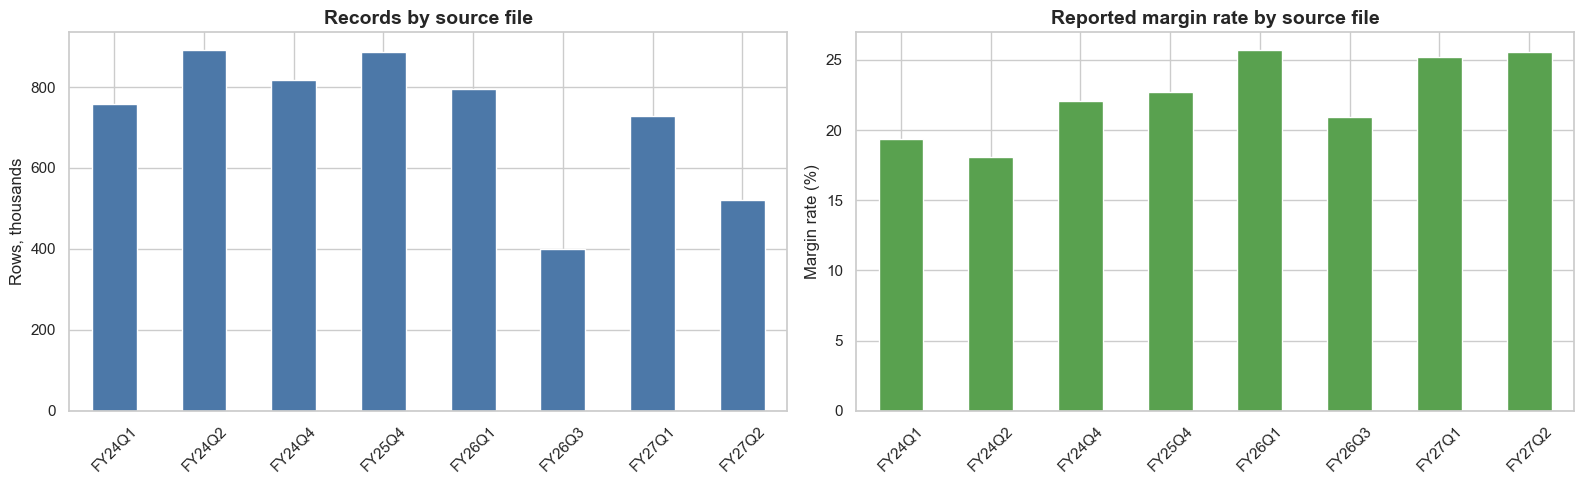

In [3]:
file_summary = pd.DataFrame(
    {
        "rows": pd.Series(row_counts),
        "order_date_min": {
            file_name: date_range[0]
            for file_name, date_range in date_ranges.items()
        },
        "order_date_max": {
            file_name: date_range[1]
            for file_name, date_range in date_ranges.items()
        },
        "revenue": {
            file_name: numeric_sums[file_name]["revenue"]
            for file_name in row_counts
        },
        "margin": {
            file_name: numeric_sums[file_name]["margin"]
            for file_name in row_counts
        },
    }
).sort_values("order_date_min")

file_summary["margin_rate"] = safe_divide(
    file_summary["margin"],
    file_summary["revenue"],
)
file_summary["days_covered"] = (
    file_summary["order_date_max"] - file_summary["order_date_min"]
).dt.days + 1

schema_consistent = len(set(schema_by_file.values())) == 1

print(f"Consistent 35-column schema: {schema_consistent}")
display(file_summary)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5),
)

plot_summary = file_summary.copy()
plot_summary.index = plot_summary.index.str.replace(
    "synthesized_",
    "",
    regex=False,
).str.replace(
    ".csv",
    "",
    regex=False,
)

plot_summary["rows"].div(1_000).plot.bar(
    ax=axes[0],
    color="#4C78A8",
)
axes[0].set_title("Records by source file")
axes[0].set_xlabel("")
axes[0].set_ylabel("Rows, thousands")
axes[0].tick_params(axis="x", rotation=45)

plot_summary["margin_rate"].mul(100).plot.bar(
    ax=axes[1],
    color="#59A14F",
)
axes[1].set_title("Reported margin rate by source file")
axes[1].set_xlabel("")
axes[1].set_ylabel("Margin rate (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Interpretation checkpoint:** filenames follow `order_date`, while `quarter_fiscal` appears tied to operational timing and can spill into later quarters. Model splits should use a clearly chosen event date rather than trusting filenames or mixing order, ship, and return timing.

## 3. Missing values and missingness drift

,missing_count,missing_pct
reason_of_return,"5,667,768.000",97.710
return_date,"5,667,642.000",97.708
reason_of_cancel,"5,633,526.000",97.120
rep_take_role,"4,434,949.000",76.457
accessory_category,"2,698,263.000",46.517
city,"1,261,958.000",21.756
tax,"451,414.000",7.782
invoice_revenue_country_currency,"261,592.000",4.510
invoice_quantity,"261,592.000",4.510
ship_date,"193,305.000",3.332


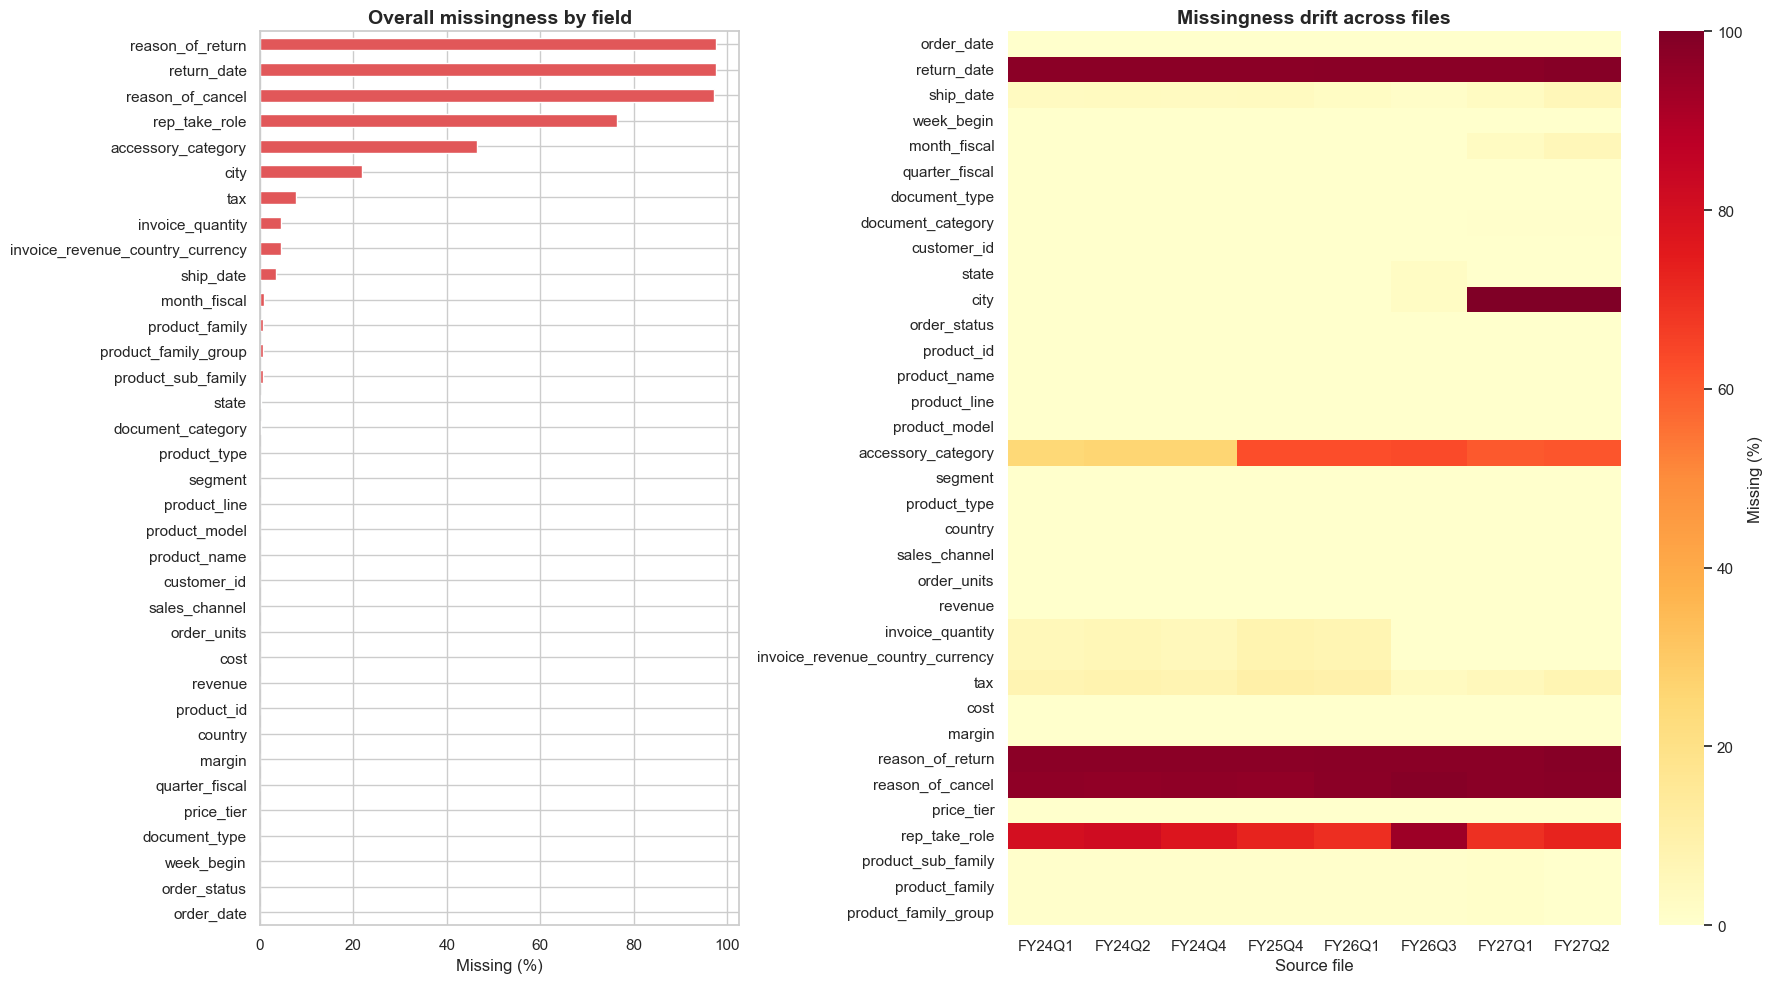

In [4]:
missing_by_file = pd.DataFrame(
    {
        file_name: {
            column: count / row_counts[file_name]
            for column, count in counts.items()
        }
        for file_name, counts in missing_counts.items()
    }
).fillna(0)

missing_overall = pd.DataFrame(
    {
        "missing_count": missing_by_file.mul(
            pd.Series(row_counts),
            axis=1,
        ).sum(axis=1)
    }
)
missing_overall["missing_pct"] = (
    missing_overall["missing_count"] / TOTAL_ROWS * 100
)
missing_overall = missing_overall.sort_values(
    "missing_pct",
    ascending=False,
)

display(missing_overall)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 10),
    gridspec_kw={"width_ratios": [1, 1.6]},
)

missing_overall["missing_pct"].sort_values().plot.barh(
    ax=axes[0],
    color="#E15759",
)
axes[0].set_title("Overall missingness by field")
axes[0].set_xlabel("Missing (%)")
axes[0].set_ylabel("")

heatmap_data = missing_by_file.mul(100)
heatmap_data.columns = heatmap_data.columns.str.replace(
    "synthesized_",
    "",
    regex=False,
).str.replace(
    ".csv",
    "",
    regex=False,
)

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    ax=axes[1],
    cbar_kws={"label": "Missing (%)"},
)
axes[1].set_title("Missingness drift across files")
axes[1].set_xlabel("Source file")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

Missing values must not all be treated alike:

- `return_date` and `reason_of_return` are structurally missing for non-return rows.
- `reason_of_cancel` is structurally missing outside cancellations.
- `invoice_quantity` and invoice revenue can be absent for orders that have not invoiced.
- `city` changes from masked/populated to 100% missing in FY27Q1–Q2, which is a material schema drift.
- `month_fiscal`, `document_category`, product hierarchy, and core segmentation blanks are unexpected and should be monitored.

For modeling, add explicit missing indicators only when the value would truly be known at the pricing decision time.

## 4. Category imbalance and label concentration

,column,unique_levels,largest_class_pct,largest_class
1,document_type,4,96.092,Invoice
3,order_status,4,94.375,SHIPS
7,sales_channel,9,87.971,Direct
6,country,2,82.963,US
2,document_category,7,80.307,Standard Invoice
11,rep_take_role,3,77.664,Tele
10,price_tier,12,75.798,$0 - $299
4,segment,3,73.229,Enterprise
9,reason_of_cancel,28,58.665,Order cancelled by customer request
12,product_family_group,12,35.538,Product Group Star Ground


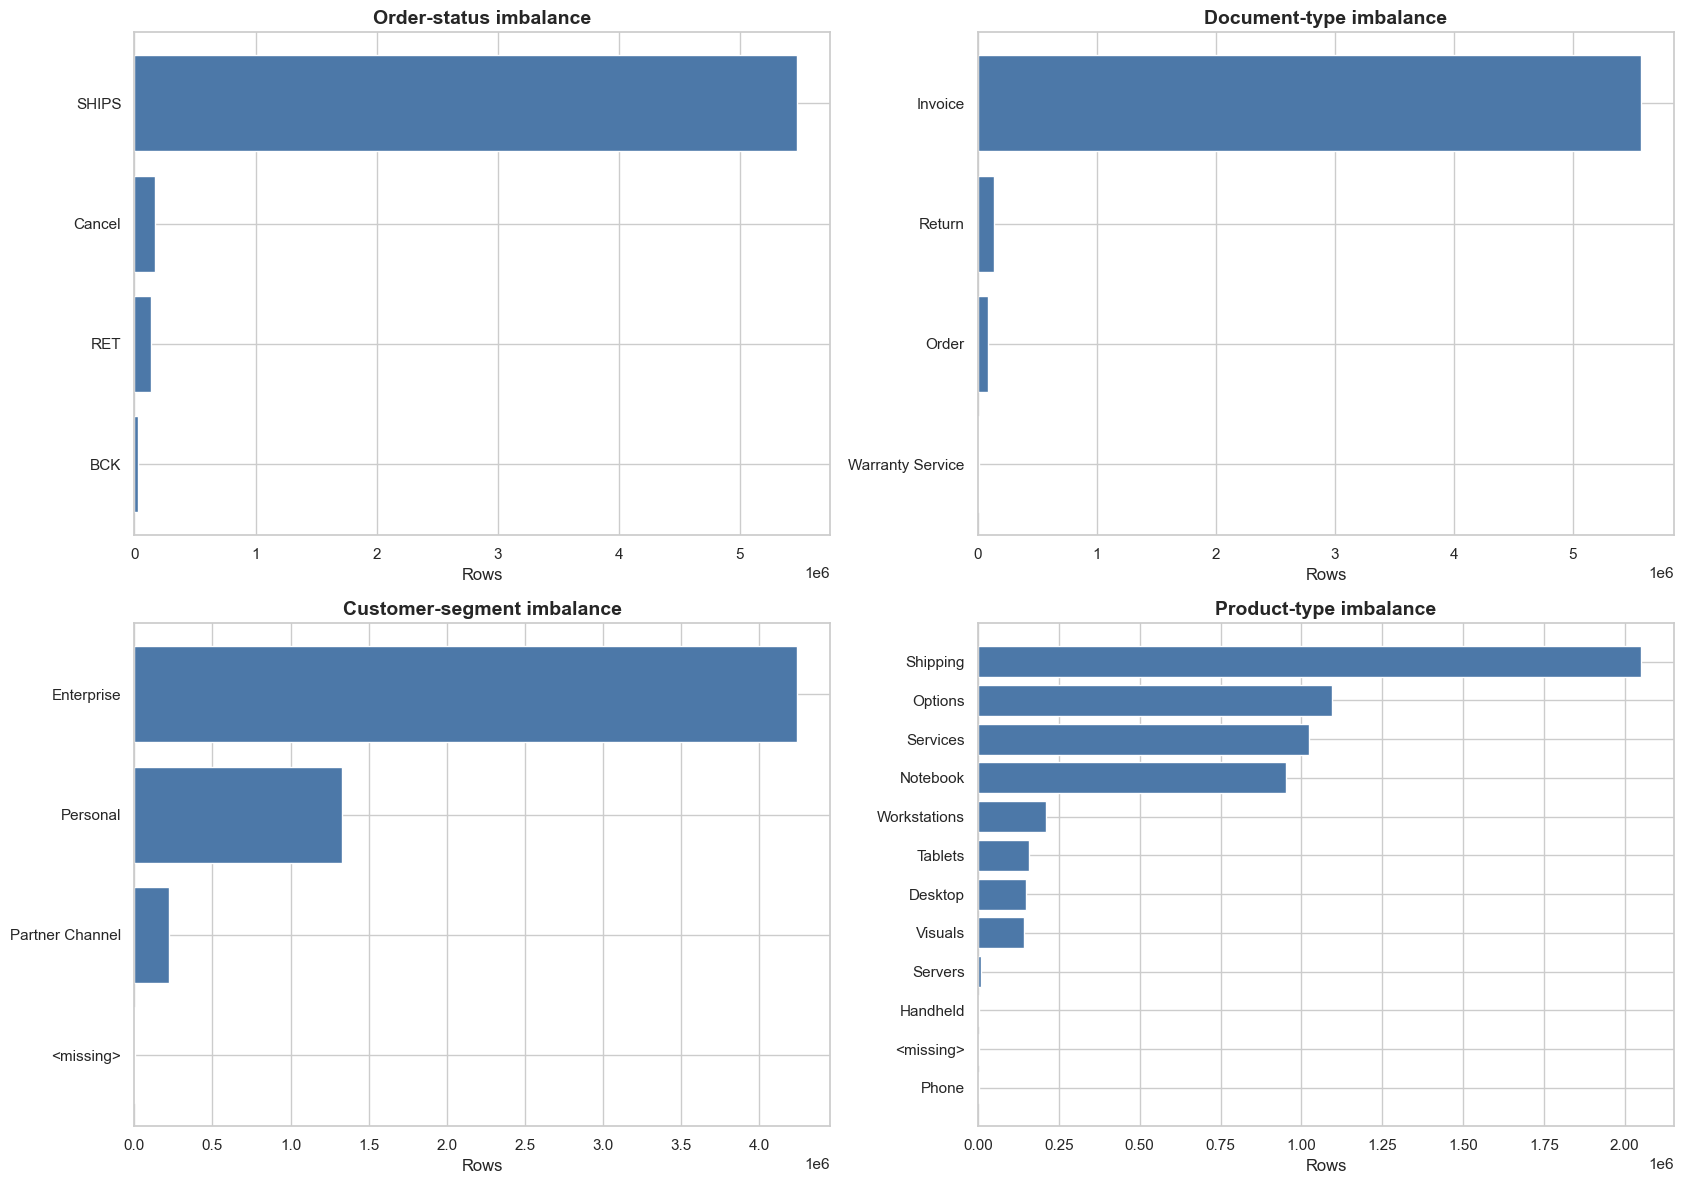

In [5]:
def counts_frame(column):
    frame = pd.DataFrame(
        category_counts[column].most_common(),
        columns=[column, "count"],
    )
    frame["share_pct"] = frame["count"] / TOTAL_ROWS * 100
    return frame


imbalance_summary = []

for column in CATEGORY_COLUMNS:
    frame = counts_frame(column)
    non_missing = frame.loc[frame[column] != "<missing>"]
    top_share = non_missing["count"].iloc[0] / non_missing["count"].sum()
    imbalance_summary.append(
        {
            "column": column,
            "unique_levels": len(non_missing),
            "largest_class_pct": top_share * 100,
            "largest_class": non_missing[column].iloc[0],
        }
    )

imbalance_summary = pd.DataFrame(imbalance_summary).sort_values(
    "largest_class_pct",
    ascending=False,
)

display(imbalance_summary)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 12),
)

for ax, column, title in zip(
    axes.flat,
    [
        "order_status",
        "document_type",
        "segment",
        "product_type",
    ],
    [
        "Order-status imbalance",
        "Document-type imbalance",
        "Customer-segment imbalance",
        "Product-type imbalance",
    ],
):
    frame = counts_frame(column).head(12).sort_values("count")
    ax.barh(
        frame[column],
        frame["count"],
        color="#4C78A8",
    )
    ax.set_title(title)
    ax.set_xlabel("Rows")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

**Modeling implication:** cancellation and return prediction are strongly imbalanced problems. Accuracy will be misleading. Prefer precision–recall AUC, recall at an operationally acceptable precision, calibration, and cost-weighted metrics. Pricing models should also report performance separately for Enterprise, Personal, Partner Channel, country, and major product types.

## 5. Exact duplicates and potential duplicate business lines

Multiple rows for the same customer and date are not automatically duplicates: one commercial transaction can contain separate product, accessory, service, and shipping lines. Because the source has no `order_id` or line identifier, this section distinguishes:

- **Exact duplicate rows:** every supplied column is identical. These are strong candidates for ingestion duplication.
- **Potential duplicate business lines:** selected transaction fields are identical. These require source-system review and must not be deleted automatically.

The reported count is the number of excess rows after retaining one representative of each repeated pattern. Hash collisions are theoretically possible but extremely unlikely.

,check,duplicate_groups,excess_rows,rows_in_duplicate_groups,largest_group,excess_row_pct
0,Exact duplicate rows,247197,572054,819251,698,9.862
1,Potential duplicate business lines,373471,2883595,3257066,6687,49.712


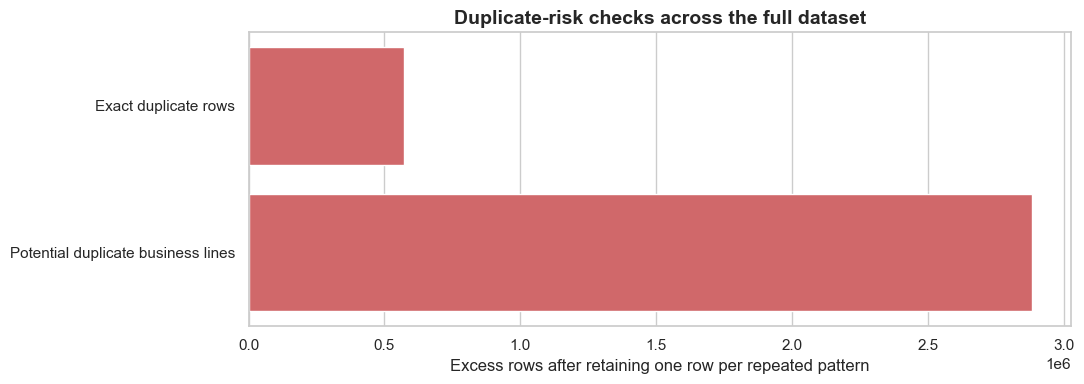

In [6]:
DUPLICATE_KEY_COLUMNS = [
    "order_date",
    "customer_id",
    "product_id",
    "document_type",
    "document_category",
    "order_status",
    "order_units",
    "revenue",
    "invoice_quantity",
    "invoice_revenue_country_currency",
]

exact_hash_parts = []
candidate_hash_parts = []

for file_path in CSV_FILES:
    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE,
        dtype="string",
        keep_default_na=False,
    ):
        normalized_chunk = chunk.fillna("")

        exact_hash = pd.util.hash_pandas_object(
            normalized_chunk,
            index=False,
        ).to_numpy(dtype="uint64")

        candidate_hash = pd.util.hash_pandas_object(
            normalized_chunk[DUPLICATE_KEY_COLUMNS],
            index=False,
        ).to_numpy(dtype="uint64")

        exact_hash_parts.append(exact_hash)
        candidate_hash_parts.append(candidate_hash)


def summarize_hash_duplicates(hash_parts):
    hashes = np.concatenate(hash_parts)
    hashes.sort()

    unique_hashes, counts = np.unique(
        hashes,
        return_counts=True,
    )
    repeated_counts = counts[counts.gt(1)] if isinstance(counts, pd.Series) else counts[counts > 1]

    return {
        "duplicate_groups": int(len(repeated_counts)),
        "excess_rows": int((repeated_counts - 1).sum()),
        "rows_in_duplicate_groups": int(repeated_counts.sum()),
        "largest_group": int(repeated_counts.max()) if len(repeated_counts) else 1,
    }


exact_duplicate_summary = summarize_hash_duplicates(exact_hash_parts)
candidate_duplicate_summary = summarize_hash_duplicates(candidate_hash_parts)

duplicate_summary = pd.DataFrame(
    [
        {
            "check": "Exact duplicate rows",
            **exact_duplicate_summary,
        },
        {
            "check": "Potential duplicate business lines",
            **candidate_duplicate_summary,
        },
    ]
)

duplicate_summary["excess_row_pct"] = (
    duplicate_summary["excess_rows"] / TOTAL_ROWS * 100
)

display(duplicate_summary)

fig, ax = plt.subplots(figsize=(11, 4))

sns.barplot(
    data=duplicate_summary,
    x="excess_rows",
    y="check",
    ax=ax,
    color="#E15759",
)
ax.set_title("Duplicate-risk checks across the full dataset")
ax.set_xlabel("Excess rows after retaining one row per repeated pattern")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

del exact_hash_parts
del candidate_hash_parts

**Interpretation:** exact duplicates can be quarantined after confirming the ingestion process. Potential business-line duplicates should remain until a true `order_id` and `order_line_id` are supplied. Without those identifiers, neither deduplication nor order-level cancellation and return rates can be made fully reliable.

## 6. Data-quality rules and financial reconciliation

,affected_rows,share_pct
negative_margin,2616526,45.108
zero_revenue,2119121,36.533
nonpositive_order_units,132967,2.292
negative_revenue,124413,2.145
margin_mismatch_gt_0_02,13780,0.238
ship_before_order,130,0.002
return_before_ship,0,0.000
unparseable_order_date,0,0.000
invoice_qty_without_invoice_revenue,0,0.000
invoice_revenue_without_qty,0,0.000


,revenue,margin,cost,revenue_minus_cost,reported_minus_calculated_margin
synthesized_FY24Q1.csv,"322,938,910.180","62,650,861.079","260,287,907.293","62,651,002.887",-141.808
synthesized_FY24Q2.csv,"356,539,471.410","64,557,530.485","291,981,943.010","64,557,528.400",2.084
synthesized_FY24Q4.csv,"324,770,881.280","71,606,003.034","253,164,879.187","71,606,002.093",0.941
synthesized_FY25Q4.csv,"390,814,175.670","88,809,427.403","302,004,618.566","88,809,557.104",-129.701
synthesized_FY26Q1.csv,"401,707,810.740","103,183,774.713","298,524,033.011","103,183,777.729",-3.016
synthesized_FY26Q3.csv,"98,497,959.860","20,645,789.698","77,852,170.000","20,645,789.860",-0.162
synthesized_FY27Q1.csv,"460,139,722.330","115,978,522.615","344,161,196.120","115,978,526.210",-3.595
synthesized_FY27Q2.csv,"329,228,959.030","84,265,910.526","244,963,045.900","84,265,913.130",-2.604


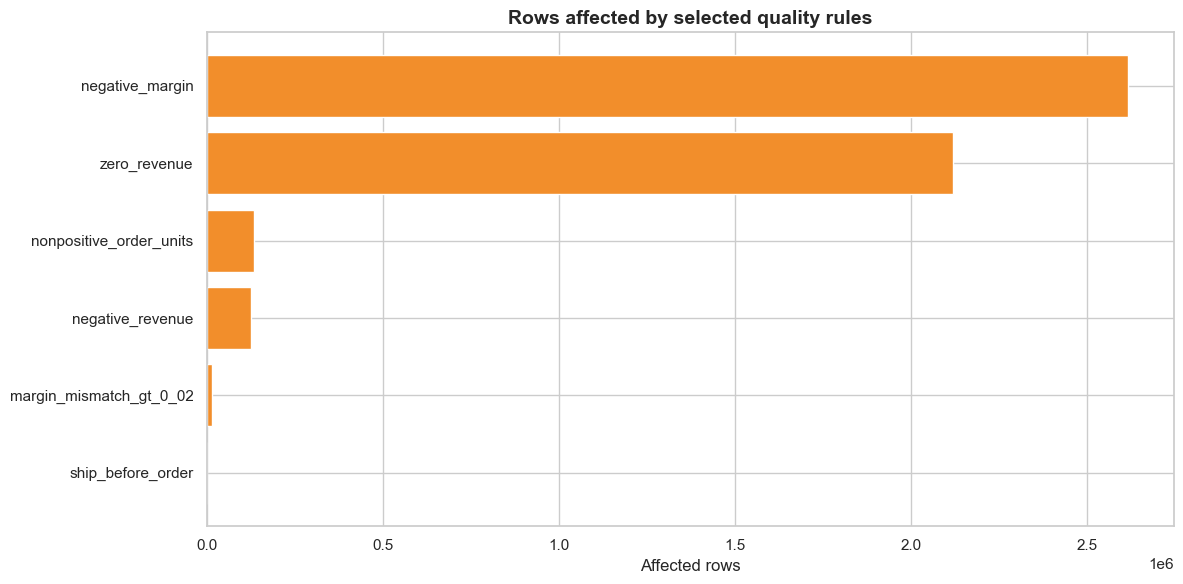

In [7]:
quality_by_file = pd.DataFrame(quality_counts).fillna(0).astype("int64")
quality_overall = quality_by_file.sum(axis=1).to_frame("affected_rows")
quality_overall["share_pct"] = (
    quality_overall["affected_rows"] / TOTAL_ROWS * 100
)
quality_overall = quality_overall.sort_values(
    "affected_rows",
    ascending=False,
)

display(quality_overall)

reconciliation = file_summary[["revenue", "margin"]].copy()
reconciliation["cost"] = pd.Series(
    {
        file_name: numeric_sums[file_name]["cost"]
        for file_name in row_counts
    }
)
reconciliation["revenue_minus_cost"] = (
    reconciliation["revenue"] - reconciliation["cost"]
)
reconciliation["reported_minus_calculated_margin"] = (
    reconciliation["margin"] - reconciliation["revenue_minus_cost"]
)

display(reconciliation)

fig, ax = plt.subplots(figsize=(12, 6))

plot_quality = quality_overall.loc[
    quality_overall["affected_rows"].gt(0),
    "affected_rows",
].sort_values()

ax.barh(
    plot_quality.index,
    plot_quality.values,
    color="#F28E2B",
)
ax.set_title("Rows affected by selected quality rules")
ax.set_xlabel("Affected rows")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

## 7. Price, margin, and shipping distributions

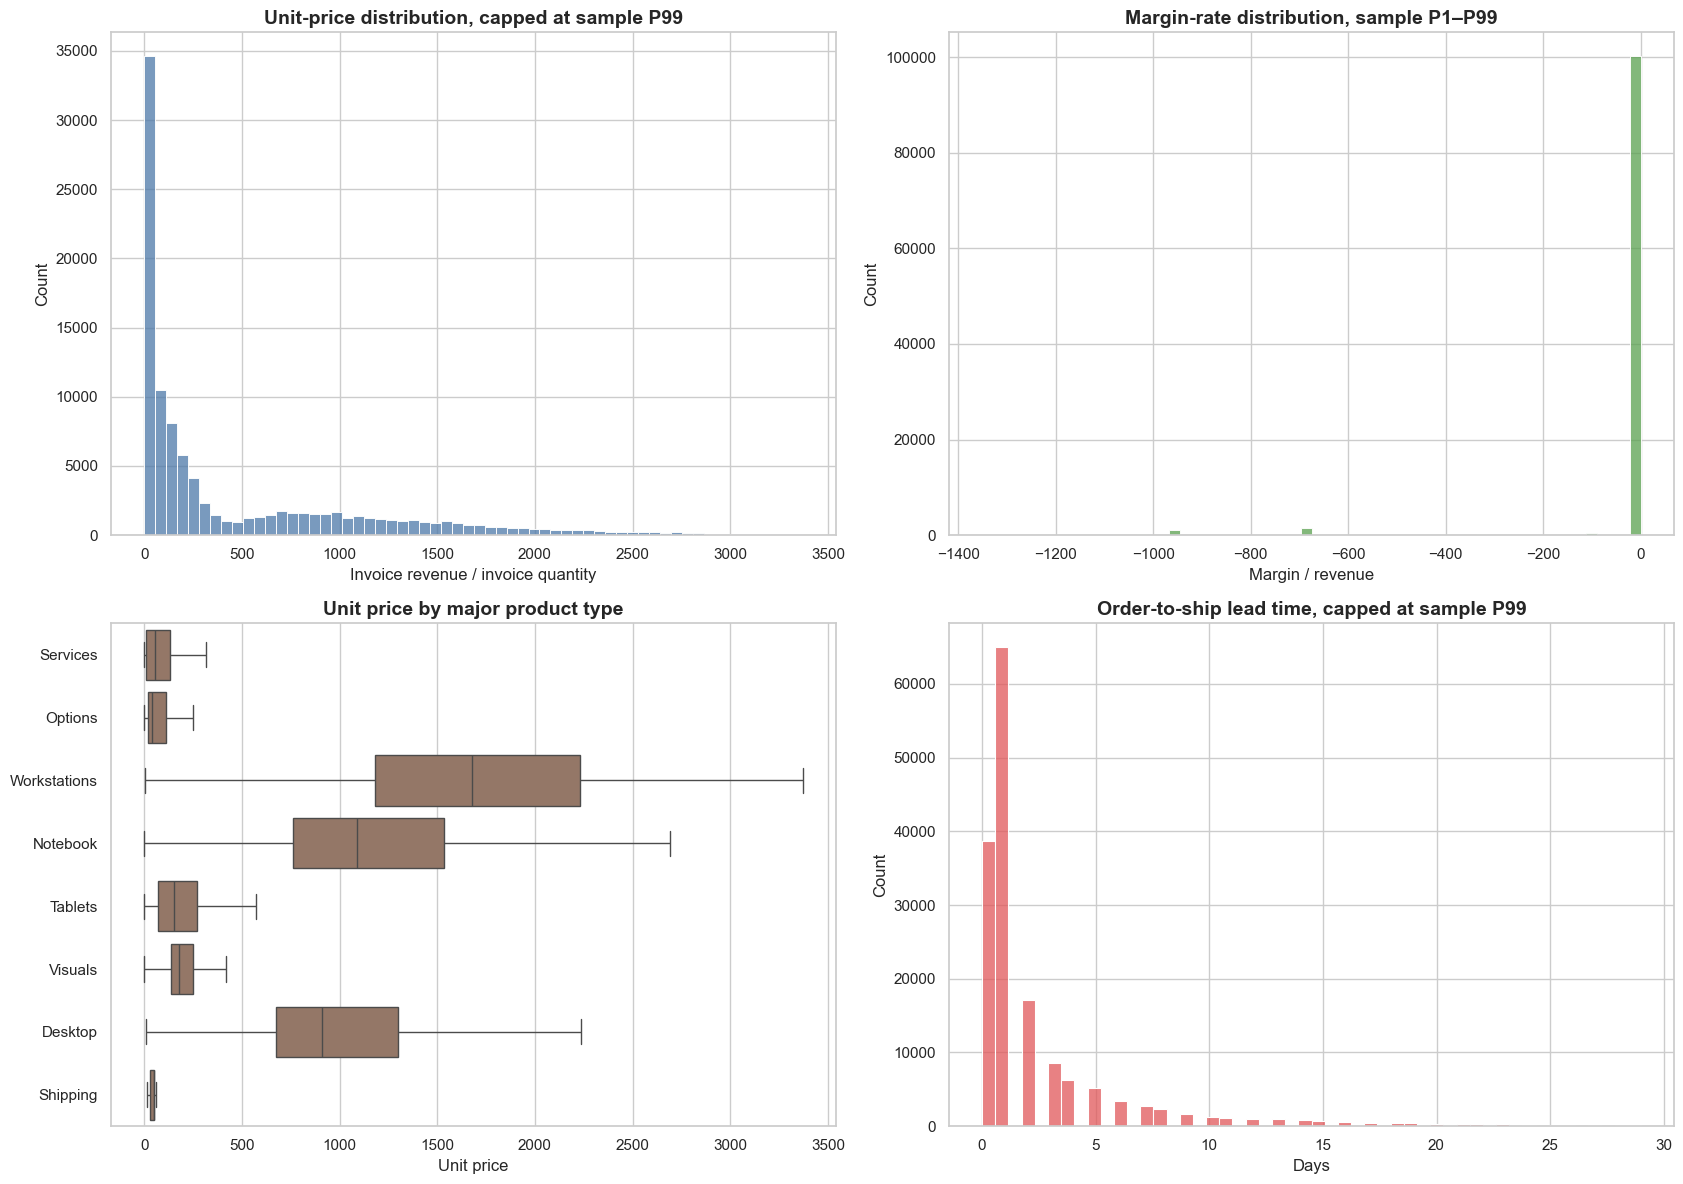

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
unit_price,"160,069.000",362.853,764.989,-0.000,0.000,0.000,0.000,31.900,319.990,"1,799.000","2,989.621","89,419.203"
margin_rate,"106,918.000",-57.353,329.353,"-21,862.000","-1,351.000",-315.000,0.035,0.275,0.522,0.987,1.000,1.016
shipping_days,"162,389.000",2.914,5.998,-1.000,0.000,0.000,1.000,1.000,3.000,12.000,29.000,225.000
revenue,"168,000.000",458.917,"2,289.215","-79,200.000",-549.000,0.000,0.000,23.280,336.000,"2,111.996","5,008.299","275,000.000"
cost,"168,000.000",354.456,"1,964.784","-147,764.430",-536.246,0.000,0.010,10.130,206.250,"1,643.920","3,900.154","228,192.000"
margin,"168,000.000",104.461,"1,050.400","-83,936.680",-442.290,-82.400,-0.010,0.000,58.853,601.305,"1,797.815","215,000.000"


In [8]:
eligible_prices = sample_df.loc[
    sample_df["unit_price"].gt(0)
    & sample_df["unit_price"].replace([np.inf, -np.inf], np.nan).notna()
].copy()

price_upper = eligible_prices["unit_price"].quantile(0.99)
margin_lower = sample_df["margin_rate"].quantile(0.01)
margin_upper = sample_df["margin_rate"].quantile(0.99)
shipping_upper = sample_df["shipping_days"].quantile(0.99)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 12),
)

sns.histplot(
    data=eligible_prices.loc[eligible_prices["unit_price"].le(price_upper)],
    x="unit_price",
    bins=60,
    ax=axes[0, 0],
    color="#4C78A8",
)
axes[0, 0].set_title("Unit-price distribution, capped at sample P99")
axes[0, 0].set_xlabel("Invoice revenue / invoice quantity")

sns.histplot(
    data=sample_df.loc[
        sample_df["margin_rate"].between(margin_lower, margin_upper)
    ],
    x="margin_rate",
    bins=60,
    ax=axes[0, 1],
    color="#59A14F",
)
axes[0, 1].set_title("Margin-rate distribution, sample P1–P99")
axes[0, 1].set_xlabel("Margin / revenue")

sns.boxplot(
    data=eligible_prices.loc[
        eligible_prices["product_type"].isin(
            eligible_prices["product_type"].value_counts().head(8).index
        )
        & eligible_prices["unit_price"].le(price_upper)
    ],
    x="unit_price",
    y="product_type",
    ax=axes[1, 0],
    color="#9C755F",
    showfliers=False,
)
axes[1, 0].set_title("Unit price by major product type")
axes[1, 0].set_xlabel("Unit price")
axes[1, 0].set_ylabel("")

sns.histplot(
    data=sample_df.loc[
        sample_df["shipping_days"].between(0, shipping_upper)
    ],
    x="shipping_days",
    bins=50,
    ax=axes[1, 1],
    color="#E15759",
)
axes[1, 1].set_title("Order-to-ship lead time, capped at sample P99")
axes[1, 1].set_xlabel("Days")

plt.tight_layout()
plt.show()

display(
    sample_df[
        [
            "unit_price",
            "margin_rate",
            "shipping_days",
            "revenue",
            "cost",
            "margin",
        ]
    ].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    ).T
)

## 8. Exact monthly pricing panel and time drift

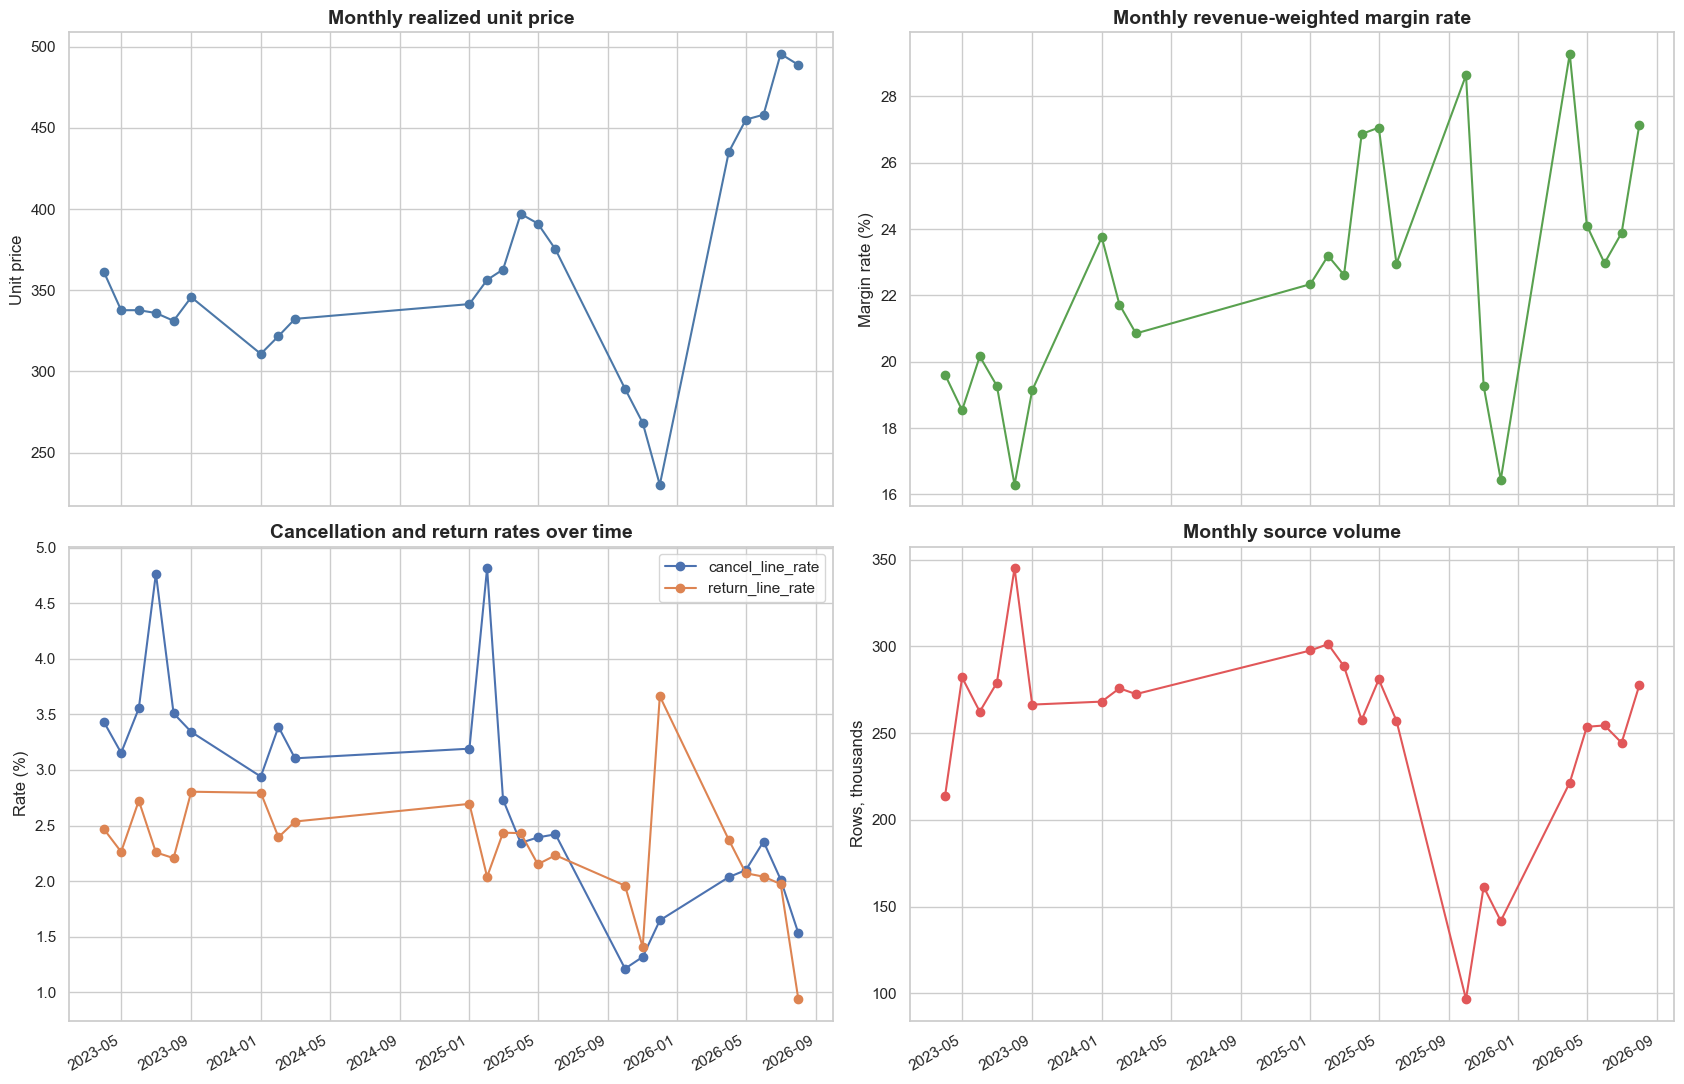

,row_count,invoice_line_count,cancel_line_count,return_line_count,order_units,revenue,invoice_quantity,invoice_revenue,cost,margin,realized_unit_price,margin_rate,cancel_line_rate,return_line_rate
month,,,,,,,,,,,,,,
2023-04-01,213606,205491,7326,5269,"270,786.000","92,995,974.490","256,476.000","92,602,100.220","74,756,519.615","18,239,373.906",361.056,0.196,0.034,0.025
2023-05-01,282120,274112,8898,6387,"372,148.000","120,166,709.030","353,878.000","119,505,715.410","97,887,933.035","22,278,714.079",337.703,0.185,0.032,0.023
2023-06-01,262434,252547,9328,7148,"335,890.000","109,776,226.660","318,157.000","107,449,294.150","87,643,454.642","22,132,773.094",337.724,0.202,0.036,0.027
2023-07-01,279095,269033,13303,6304,"352,142.000","112,159,085.990","328,091.000","110,236,839.500","90,541,952.819","21,617,133.019",335.995,0.193,0.048,0.023
2023-08-01,345101,335589,12111,7617,"429,828.000","134,633,986.360","407,646.000","135,004,741.560","112,699,870.696","21,934,115.660",331.181,0.163,0.035,0.022
2023-09-01,266491,257609,8907,7474,"334,022.000","109,746,399.060","316,493.000","109,422,184.980","88,740,119.495","21,006,281.806",345.733,0.191,0.033,0.028
2024-01-01,268206,256295,7887,7496,"343,994.000","101,477,165.140","327,348.000","101,743,456.280","77,377,019.865","24,100,146.895",310.811,0.237,0.029,0.028
2024-02-01,275890,266386,9348,6610,"353,864.000","108,074,429.900","337,375.000","108,548,688.290","84,596,387.001","23,478,042.409",321.745,0.217,0.034,0.024
2024-03-01,272540,261227,8462,6913,"364,848.000","115,219,286.240","345,558.000","114,858,400.440","91,191,472.322","24,027,813.729",332.385,0.209,0.031,0.025


,panel_rows,active_products,zero_invoice_quantity_groups,negative_margin_groups
month,,,,
2023-04-01,10154,4056,523,3140
2023-05-01,10459,4053,587,3061
2023-06-01,10506,4069,620,3432
2023-07-01,10335,3908,695,2854
2023-08-01,11344,4013,622,3809
2023-09-01,10009,3738,510,3020
2024-01-01,10519,4159,496,3538
2024-02-01,10204,4029,506,2910
2024-03-01,10599,4213,539,3123


In [9]:
monthly_summary = monthly_panel.groupby("month").agg(
    row_count=("row_count", "sum"),
    invoice_line_count=("invoice_line_count", "sum"),
    cancel_line_count=("cancel_line_count", "sum"),
    return_line_count=("return_line_count", "sum"),
    order_units=("order_units", "sum"),
    revenue=("revenue", "sum"),
    invoice_quantity=("invoice_quantity", "sum"),
    invoice_revenue=("invoice_revenue", "sum"),
    cost=("cost", "sum"),
    margin=("margin", "sum"),
)

monthly_summary["realized_unit_price"] = safe_divide(
    monthly_summary["invoice_revenue"],
    monthly_summary["invoice_quantity"],
)
monthly_summary["margin_rate"] = safe_divide(
    monthly_summary["margin"],
    monthly_summary["revenue"],
)
monthly_summary["cancel_line_rate"] = safe_divide(
    monthly_summary["cancel_line_count"],
    monthly_summary["row_count"],
)
monthly_summary["return_line_rate"] = safe_divide(
    monthly_summary["return_line_count"],
    monthly_summary["row_count"],
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11),
    sharex=True,
)

monthly_summary["realized_unit_price"].plot(
    ax=axes[0, 0],
    marker="o",
    color="#4C78A8",
)
axes[0, 0].set_title("Monthly realized unit price")
axes[0, 0].set_ylabel("Unit price")

monthly_summary["margin_rate"].mul(100).plot(
    ax=axes[0, 1],
    marker="o",
    color="#59A14F",
)
axes[0, 1].set_title("Monthly revenue-weighted margin rate")
axes[0, 1].set_ylabel("Margin rate (%)")

monthly_summary[["cancel_line_rate", "return_line_rate"]].mul(100).plot(
    ax=axes[1, 0],
    marker="o",
)
axes[1, 0].set_title("Cancellation and return rates over time")
axes[1, 0].set_ylabel("Rate (%)")

monthly_summary["row_count"].div(1_000).plot(
    ax=axes[1, 1],
    marker="o",
    color="#E15759",
)
axes[1, 1].set_title("Monthly source volume")
axes[1, 1].set_ylabel("Rows, thousands")

for ax in axes.flat:
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

display(monthly_summary)

monthly_coverage = monthly_panel.groupby("month").agg(
    panel_rows=("product_id", "size"),
    active_products=("product_id", "nunique"),
    zero_invoice_quantity_groups=("invoice_quantity", lambda series: series.eq(0).sum()),
    negative_margin_groups=("margin", lambda series: series.lt(0).sum()),
)

display(monthly_coverage)

### Monthly panel definition

The exact panel grain is:

`month × product_id × product_type × product_family_group × segment × country × sales_channel`

Rates are calculated after aggregation from their component totals. This avoids averaging row-level percentages. Because no order identifier exists, cancellation and return metrics are explicitly labeled as **line rates**, not order rates.

,products,products_with_1_month,products_with_lt_3_months,products_with_lt_6_months,median_observed_months
0,19123,5722,8536,13355,3.000


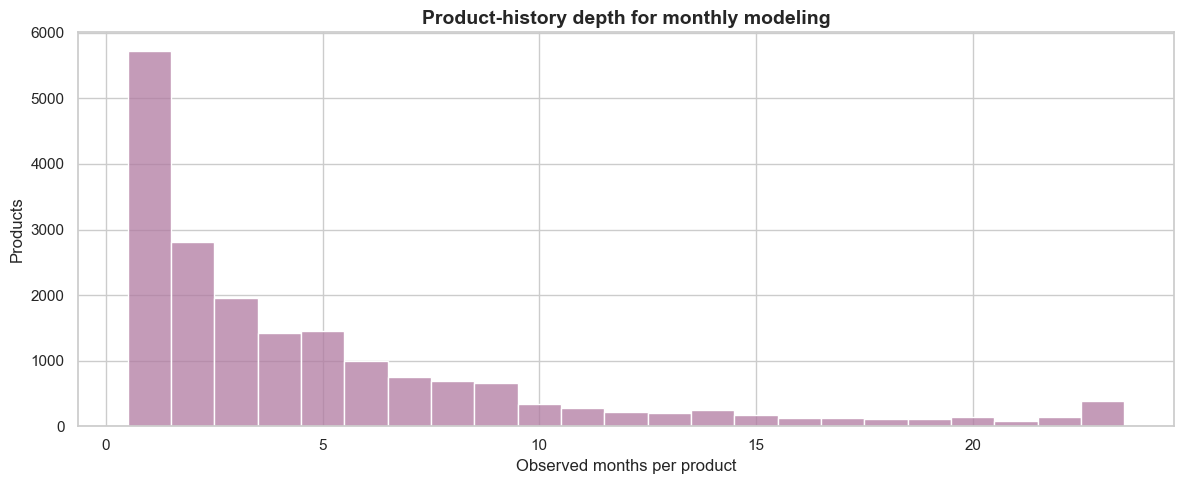

Monthly panel saved to: Data/monthly_pricing_panel.csv.gz
Monthly panel shape: (218246, 21)


In [10]:
product_history = monthly_panel.groupby("product_id").agg(
    observed_months=("month", "nunique"),
    first_month=("month", "min"),
    last_month=("month", "max"),
    total_rows=("row_count", "sum"),
    total_invoice_quantity=("invoice_quantity", "sum"),
)

history_summary = pd.DataFrame(
    {
        "products": [len(product_history)],
        "products_with_1_month": [product_history["observed_months"].eq(1).sum()],
        "products_with_lt_3_months": [product_history["observed_months"].lt(3).sum()],
        "products_with_lt_6_months": [product_history["observed_months"].lt(6).sum()],
        "median_observed_months": [product_history["observed_months"].median()],
    }
)

display(history_summary)

fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=product_history,
    x="observed_months",
    discrete=True,
    ax=ax,
    color="#B07AA1",
)
ax.set_title("Product-history depth for monthly modeling")
ax.set_xlabel("Observed months per product")
ax.set_ylabel("Products")

plt.tight_layout()
plt.show()

MONTHLY_OUTPUT_PATH = DATA_DIR / "monthly_pricing_panel.csv.gz"

monthly_panel.sort_values(
    [
        "month",
        "product_id",
        "segment",
        "country",
        "sales_channel",
    ]
).to_csv(
    MONTHLY_OUTPUT_PATH,
    index=False,
    compression="gzip",
)

print(f"Monthly panel saved to: {MONTHLY_OUTPUT_PATH}")
print(f"Monthly panel shape: {monthly_panel.shape}")

## 9. Price-tier consistency and feature leakage checks

In [11]:
raw_tiers = counts_frame("price_tier")
raw_tiers["normalized_tier"] = normalize_price_tier(raw_tiers["price_tier"])

tier_collisions = raw_tiers.groupby("normalized_tier").agg(
    raw_labels=("price_tier", "nunique"),
    rows=("count", "sum"),
).sort_values(
    ["raw_labels", "rows"],
    ascending=False,
)

display(raw_tiers)
display(tier_collisions.loc[tier_collisions["raw_labels"].gt(1)])

potential_leakage = pd.DataFrame(
    [
        ("invoice_revenue_country_currency", "Directly determines realized unit price"),
        ("revenue", "Post-order financial outcome and possible target component"),
        ("cost", "May be unavailable or revised at quote time"),
        ("margin", "Directly derived from revenue and cost"),
        ("price_tier", "Likely derived from price; circular if predicting price"),
        ("order_status", "Known after pricing; leaks cancellation outcome"),
        ("reason_of_cancel", "Post-outcome field"),
        ("return_date", "Post-outcome field"),
        ("reason_of_return", "Post-outcome field"),
        ("ship_date", "May occur after the pricing decision"),
        ("invoice_quantity", "May differ from quantity known at quote time"),
    ],
    columns=["field", "risk"],
)

display(potential_leakage)

,price_tier,count,share_pct,normalized_tier
0,$0 - $299,4396750,75.798,$0-$299
1,$700 - $999,237171,4.089,$700-$999
2,$1000 - $1299,220003,3.793,$1000-$1299
3,$2000+,185934,3.205,$2000+
4,$500 - $699,151459,2.611,$500-$699
5,$1300 - $1499,117749,2.030,$1300-$1499
6,$300 - $499,114720,1.978,$300-$499
7,$1700 - $1999,103909,1.791,$1700-$1999
8,$1500 - $1699,103776,1.789,$1500-$1699
9,$700 - $999,78245,1.349,$700-$999


,raw_labels,rows
normalized_tier,,
$700-$999,2,315416
$500-$699,2,192378
$300-$499,2,164693


,field,risk
0,invoice_revenue_country_currency,Directly determines realized unit price
1,revenue,Post-order financial outcome and possible targ...
2,cost,May be unavailable or revised at quote time
3,margin,Directly derived from revenue and cost
4,price_tier,Likely derived from price; circular if predict...
5,order_status,Known after pricing; leaks cancellation outcome
6,reason_of_cancel,Post-outcome field
7,return_date,Post-outcome field
8,reason_of_return,Post-outcome field
9,ship_date,May occur after the pricing decision


## 10. Recommended modeling cohort and validation design

There is no clean observed **offered price + purchase/no-purchase response** pair in the current schema. That limits causal price-elasticity estimation. A model trained only on completed invoices learns historical realized prices, not how demand changes when price changes.

Recommended checkpoints before modeling:

1. **Define the decision and target precisely.** Examples: recommend a quote price, estimate probability of purchase at a candidate price, predict expected margin, or flag margin-risk transactions.
2. **Create an as-of-time feature contract.** Retain only fields available when the price was set. Exclude invoice, return, cancellation, and fulfillment outcomes from training features unless they are explicitly the target.
3. **Use time-based validation.** Train on earlier quarters and validate on later quarters. Never use a random split as the primary result because products, prices, and data collection drift over time.
4. **Group related rows.** Orders contain multiple product/service/shipping lines. Split by order or customer-time group so associated lines cannot cross train and validation sets.
5. **Choose a coherent pricing grain.** Product-line rows include shipping and services, and some have zero or negative amounts. A dashboard may need separate product, accessory, service, and shipping cohorts.
6. **Handle selection bias.** Historical prices were chosen by earlier commercial rules. Elasticity requires rejected quotes, offer history, promotions, competitor price, inventory, and ideally controlled price variation.
7. **Apply guardrails.** Enforce minimum margin, permissible price bands, inventory/service constraints, customer fairness review, and manual override logging.
8. **Evaluate business value.** Track realized revenue, gross margin, conversion, cancellation, return rate, calibration, override rate, and performance by customer/product segment.

In [12]:
model_readiness = pd.DataFrame(
    [
        ("Stable product identifier", "Available", "Use product_id; monitor unseen and renamed products"),
        ("Historical realized price", "Available with caveats", "Derive only for valid positive invoice quantity"),
        ("Cost / margin", "Available with caveats", "Confirm when cost becomes known and reconcile anomalies"),
        ("Demand response at offered price", "Missing", "Add quote exposure, accepted/rejected outcome, and timestamp"),
        ("Inventory / availability", "Mostly missing", "Cancellation reasons are not a substitute for inventory snapshots"),
        ("Promotion / discount", "Missing", "Add list price, discount, coupon, and campaign fields"),
        ("Competitor price", "Missing", "Add time-stamped comparable-market prices if permissible"),
        ("Customer geography", "Unstable", "City disappears in FY27; use stable geography or remove"),
        ("Decision timestamp", "Unclear", "Document when price was presented versus ordered/invoiced"),
    ],
    columns=["requirement", "status", "action"],
)

display(model_readiness)

,requirement,status,action
0,Stable product identifier,Available,Use product_id; monitor unseen and renamed pro...
1,Historical realized price,Available with caveats,Derive only for valid positive invoice quantity
2,Cost / margin,Available with caveats,Confirm when cost becomes known and reconcile ...
3,Demand response at offered price,Missing,"Add quote exposure, accepted/rejected outcome,..."
4,Inventory / availability,Mostly missing,Cancellation reasons are not a substitute for ...
5,Promotion / discount,Missing,"Add list price, discount, coupon, and campaign..."
6,Competitor price,Missing,Add time-stamped comparable-market prices if p...
7,Customer geography,Unstable,City disappears in FY27; use stable geography ...
8,Decision timestamp,Unclear,Document when price was presented versus order...


## 11. Dashboard monitoring blueprint

The production dashboard should support filters for time, country, segment, sales channel, product hierarchy, and model version. Recommended panels:

- **Commercial outcomes:** offered price, realized unit price, conversion, revenue, margin, margin rate, cancellations, and returns
- **Model monitoring:** prediction distribution, calibration, error by cohort, drift, unseen-category rate, missing-feature rate, and fallback/override rate
- **Guardrails:** quotes below margin floor, extreme price changes, negative-margin transactions, delayed shipments, and high-return cohorts
- **Data health:** row volume, ingestion freshness, duplicate rate, invalid dates, reconciliation failures, and schema/missingness drift
- **Experimentation:** treatment/control assignment, price delta, incremental conversion, incremental margin, confidence intervals, and stopping rules

Suggested refresh grain is daily for operations and weekly/monthly for stable trend interpretation. Every KPI should state whether it is based on orders, invoice lines, units, customers, or revenue-weighted results.

## Executive findings

- The data is large enough for modeling but is a **transaction-outcome dataset**, not yet a causal dynamic-pricing dataset.
- Missingness is often structural, but the complete loss of `city` and increasing blanks in several fields show meaningful collection drift.
- Returns, cancellations, and several customer/product cohorts are imbalanced; evaluation must be cohort-aware and use suitable metrics.
- Price tiers require normalization, date formats change, and selected financial/date rules reveal anomalies that should be isolated before training.
- Realized unit price should only be calculated on a carefully filtered invoice cohort with valid positive quantities.
- The strongest immediate ML use cases are price benchmarking, expected-margin prediction, anomaly detection, and cancellation/return risk. True price optimization needs quote exposure, conversion, discount, inventory, promotion, and preferably experimental data.